# 🧠 Part A: Conceptual Understanding


### 1. What are Supervised Learning Algorithms?
Supervised learning algorithms learn from labeled data, where every input (features) has a known output (target). The model learns the mapping X → y and then predicts outputs for new, unseen data. Example: predicting house price from area, rooms, and location.

### 2. Regression vs Classification

- Regression predicts a continuous numeric value (e.g., house price = ₹45,00,000). Examples: Linear Regression, Polynomial Regression.
- Classification predicts a discrete category/label (e.g., house is "Expensive" or "Cheap"). Examples: Logistic Regression, Decision Tree.

### 3. Simple Linear Regression
It models the relationship between one independent variable (x) and one dependent variable (y) using a straight line:

- y = β₀ + β₁x + ε

Here β₀ is the intercept, β₁ is the slope (change in y per unit change in x), and ε is the error. Parameters are found by minimizing the sum of squared errors (Ordinary Least Squares).

### 4. Assumptions of Linear Regression

- I. Linearity: the relationship between X and y is linear.
- II. Independence: observations (and errors) are independent of each other.
- III. Homoscedasticity: the residuals have constant variance across all predicted values.
- IV. Normality of residuals: the errors are normally distributed.
- V. No multicollinearity (for multiple regression): the features are not highly correlated with each other.

### 5. Bias-Variance Trade-Off

- Bias is error from overly simple assumptions (the model misses the pattern).
- Variance is error from being too sensitive to the training data (the model learns noise).

Increasing model complexity lowers bias but raises variance. The goal is the sweet spot where total error is lowest.

Formula :

Total Error = Bias² + Variance + Irreducible Error

### 6. Overfitting vs Underfitting

- Underfitting: the model is too simple and performs poorly on both training and test data. Example: fitting a straight line to curved data.
- Overfitting: the model is too complex, with very high training accuracy but poor test accuracy. Example: a degree-15 polynomial that memorizes every data point, noise included.

| Model Condition | Train Error | Test Error |
|-----------------|-------------|------------|
| Underfitting    | High        | High       |
| Good fit        | Low         | Low        |
| Overfitting     | Very Low    | High       |

---
---

# 🧪 Part B: Dataset Understanding & Preparation


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load dataset
df = pd.read_excel('../Dataset/RealEstate_HousePrice_Dataset_4200.xlsx')

# Display first 5 rows
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [3]:
# Display column names

print("Columns in Dataset:")
print(df.columns.tolist())

Columns in Dataset:
['house_id', 'area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago', 'house_price_inr']


In [4]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


## 7. Identify Independent and Dependent Variables

The dataset contains information about different properties and their corresponding house prices.

The objective of this project is to predict `house_price_inr` using the available property-related features.

### Independent Variables

The independent variables are the input features used by the machine learning model:

- `area_sqft`
- `bedrooms`
- `bathrooms`
- `location_score`
- `age_years`
- `distance_city_km`
- `lot_size_sqft`
- `has_garage`
- `has_pool`
- `renovation_years_ago`

The `house_id` column is not used as a predictive feature because it is only an identifier.

### Dependent Variable

The dependent variable is:

- `house_price_inr`

This is the target variable that the model will learn to predict.

### Problem Type

This is a **Supervised Learning Regression Problem** because the target variable `house_price_inr` is a continuous numerical value.

In [5]:
# Independent variables / Features

X = df[
    [
        "area_sqft",
        "bedrooms",
        "bathrooms",
        "location_score",
        "age_years",
        "distance_city_km",
        "lot_size_sqft",
        "has_garage",
        "has_pool",
        "renovation_years_ago"
    ]
]

# Dependent variable / Target
y = df["house_price_inr"]

print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (y):")
print(y.name)

Independent Variables (X):
['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']

Dependent Variable (y):
house_price_inr


## 8. Visualize Relationships Between Features and Target Variable

In [6]:
numerical_features = [
    "area_sqft",
    "bedrooms",
    "bathrooms",
    "location_score",
    "age_years",
    "distance_city_km",
    "lot_size_sqft",
    "renovation_years_ago"
]

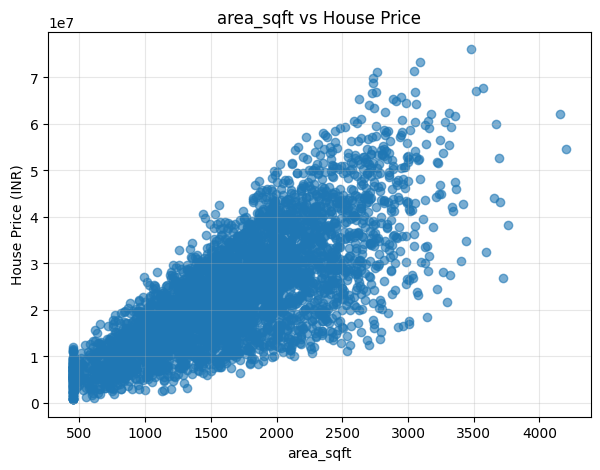

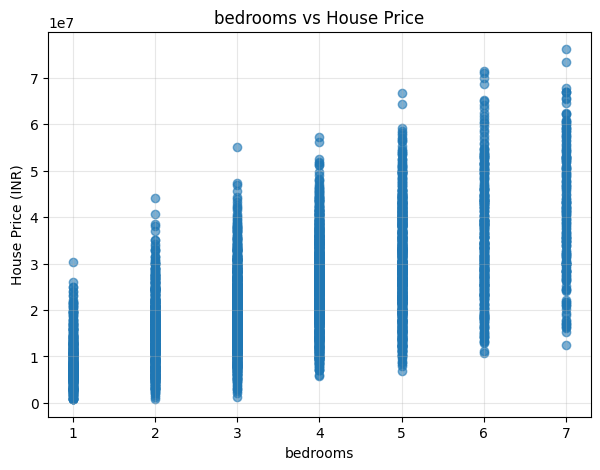

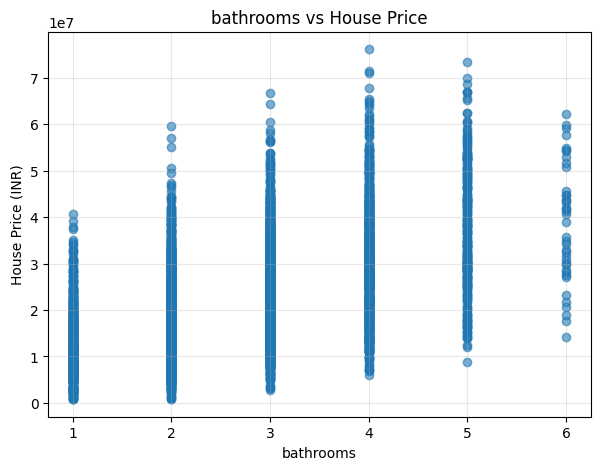

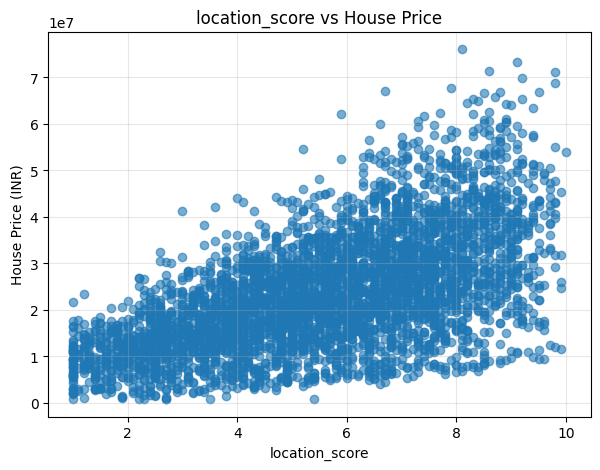

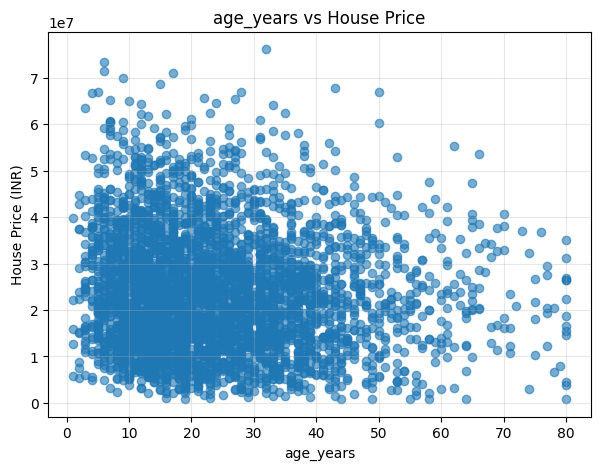

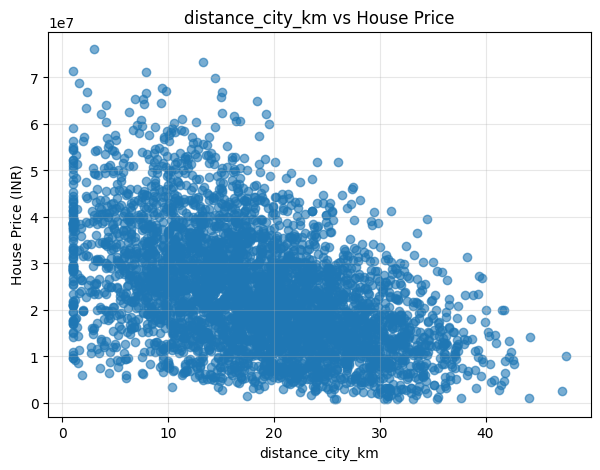

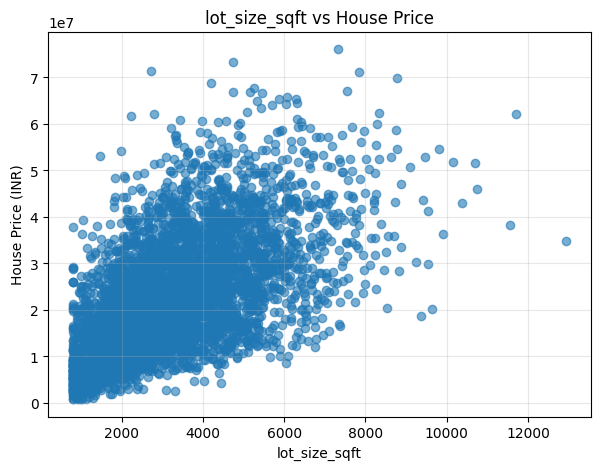

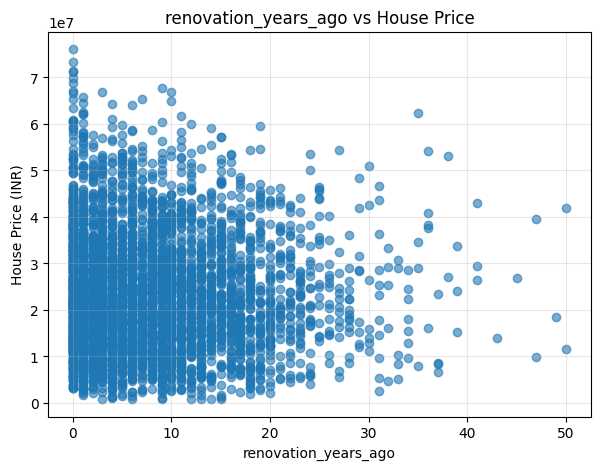

In [7]:
# Scatter Plots

for feature in numerical_features:
    plt.figure(figsize=(7, 5))
    plt.scatter(df[feature],df["house_price_inr"],alpha=0.6)
    plt.xlabel(feature)
    plt.ylabel("House Price (INR)")
    plt.title(f"{feature} vs House Price")
    plt.grid(alpha=0.3)
    plt.show()

<Figure size 700x500 with 0 Axes>

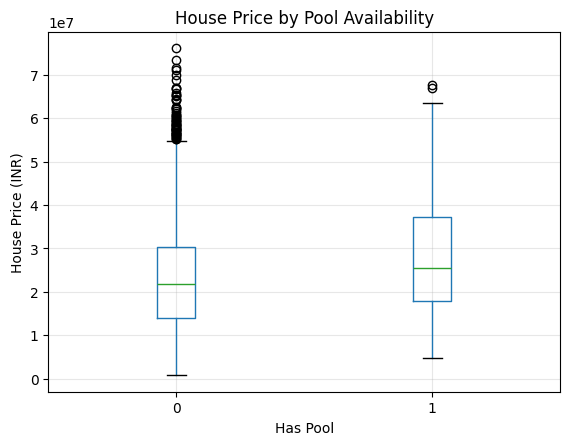

In [8]:
# Box Plot

plt.figure(figsize=(7, 5))
df.boxplot(column="house_price_inr",by="has_pool")
plt.xlabel("Has Pool")
plt.ylabel("House Price (INR)")
plt.title("House Price by Pool Availability")
plt.suptitle("")
plt.grid(alpha=0.3)
plt.show()

In [9]:
# Correlation Analysis

correlation = df[numerical_features + ["house_price_inr"]].corr()
print(correlation["house_price_inr"].sort_values(ascending=False))

house_price_inr         1.000000
area_sqft               0.755434
bedrooms                0.644772
location_score          0.588531
lot_size_sqft           0.567751
bathrooms               0.527044
renovation_years_ago   -0.037409
age_years              -0.089454
distance_city_km       -0.469431
Name: house_price_inr, dtype: float64


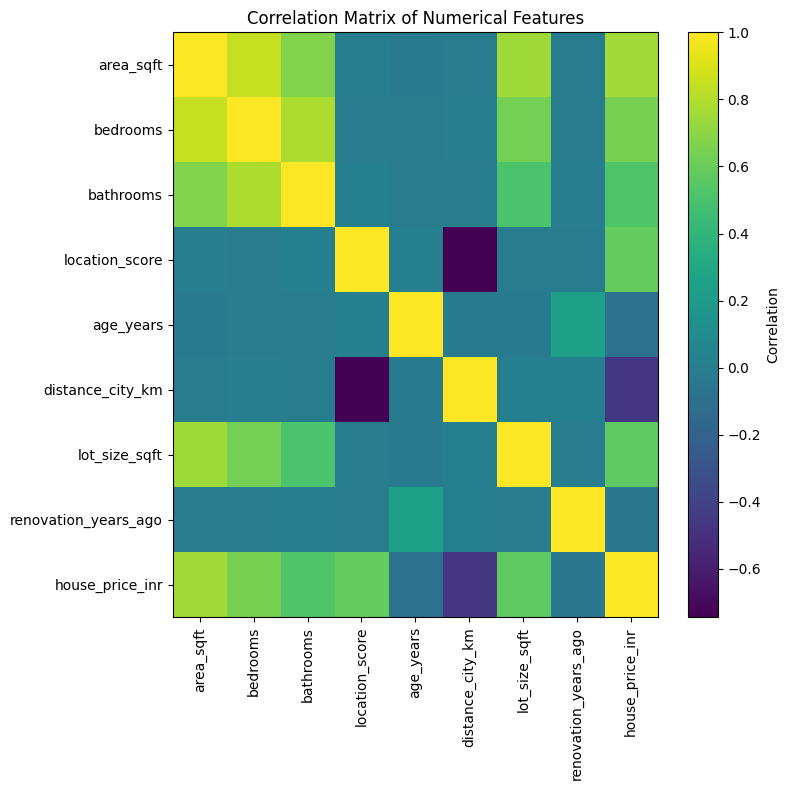

In [10]:
# Correlation Heatmap

plt.figure(figsize=(8, 8))
correlation_matrix = df[numerical_features + ["house_price_inr"]].corr()
plt.imshow(correlation_matrix,aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)),correlation_matrix.columns,rotation=90)
plt.yticks(range(len(correlation_matrix.columns)),correlation_matrix.columns)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## Interpretation

Scatter plots, box plots, and correlation analysis were used to understand the relationship between the features and `house_price_inr`.

### Key Findings

- **`area_sqft`** has the strongest positive relationship with house price (**r = 0.755**).
- **`bedrooms`** (**r = 0.645**), **`location_score`** (**r = 0.589**), **`lot_size_sqft`** (**r = 0.568**), and **`bathrooms`** (**r = 0.527**) show moderate-to-strong positive relationships.
- **`distance_city_km`** has a moderate negative relationship (**r = -0.469**), meaning properties farther from the city generally have lower prices.
- **`age_years`** (**r = -0.089**) and **`renovation_years_ago`** (**r = -0.037**) show very weak relationships with house price.
- Box plots show that houses with **garages and pools tend to have higher prices**.

### Overall Conclusion

`area_sqft` is the strongest positively correlated feature, while `distance_city_km` has the strongest negative relationship with house price. Correlation shows association, not causation.

## 9. Train-Test Split

In [11]:
from sklearn.model_selection import train_test_split  

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)
print()
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (3360, 10)
Testing Features: (840, 10)

Training Target: (3360,)
Testing Target: (840,)


## Interpretation

The dataset was divided into **80% training data** and **20% testing data** using `train_test_split()`.

- **Training set:** Used to train the machine learning models.
- **Testing set:** Used to evaluate model performance on unseen data.
- `random_state=42` was used to make the split reproducible.

This separation helps evaluate how well the model generalizes to new data.

---
---

# 📈 Part C: Simple Linear Regression

### 10. Implement Simple Linear Regression Using One Feature

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select one feature and target
X_simple = df[["area_sqft"]]
Y_simple = df["house_price_inr"]

# Split into training and testing sets
X_train_simple, X_test_simple, Y_train_simple, Y_test_simple = train_test_split(X_simple,Y_simple,test_size=0.20,random_state=42)

# Create the Simple Linear Regression model
simple_lr = LinearRegression()

# Train the model
simple_lr.fit(X_train_simple , Y_train_simple)

# Make predictions
Y_pred_simple = simple_lr.predict(X_test_simple)

# Display model parameters
print("Slope (Coefficient):", simple_lr.coef_[0])
print("Intercept:", simple_lr.intercept_)
print()
Actual_vs_Predicted = pd.DataFrame({ 'Actual': Y_test_simple , 'Predicted': Y_pred_simple })
print(Actual_vs_Predicted.head())

Slope (Coefficient): 14788.306111307536
Intercept: -1163519.1764186025

        Actual     Predicted
1743  36890986  3.440236e+07
2196  27836840  2.733355e+07
1728  15321534  2.677159e+07
3337  30812774  2.180272e+07
298   18194835  3.104541e+07


### 11. Plot Regression Line and Interpret Slope & Intercept

The regression line shows the relationship between `area_sqft` and `house_price_inr`.

$$
y = \beta_0 + \beta_1x
$$

- $\beta_0$ = Intercept
- $\beta_1$ = Slope
- $x$ = `area_sqft`
- $y$ = `house_price_inr`

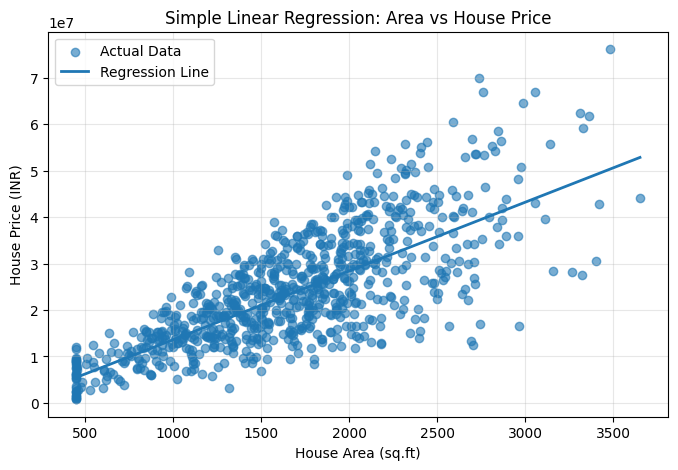

Regression Equation:
House Price = -1163519.18 + (14788.31 * area_sqft)


In [13]:
# Sort values so regression line appears correctly

sorted_indices = X_test_simple["area_sqft"].argsort()
X_sorted = X_test_simple.iloc[sorted_indices]
y_pred_sorted = simple_lr.predict(X_sorted)

# Plot actual test data

plt.figure(figsize=(8, 5))
plt.scatter(X_test_simple["area_sqft"],Y_test_simple,alpha=0.6,label="Actual Data")
plt.plot(X_sorted["area_sqft"],y_pred_sorted,linewidth=2,label="Regression Line")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.title("Simple Linear Regression: Area vs House Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

slope = simple_lr.coef_[0]
intercept = simple_lr.intercept_

print(f"Regression Equation:")
print(f"House Price = {intercept:.2f} + ({slope:.2f} * area_sqft)")



### Interpretation

- **Slope:** Represents the expected change in house price for a 1 sq.ft increase in house area. A positive slope indicates that larger houses tend to have higher predicted prices.
- **Intercept:** Represents the predicted price when area is zero. Since zero-area houses are not practical, it mainly serves as a mathematical parameter.

### Conclusion

The regression line shows a positive relationship between house area and house price.

### 12. Validate Linear Regression Assumptions

Mean Residual: 740071.2378291326


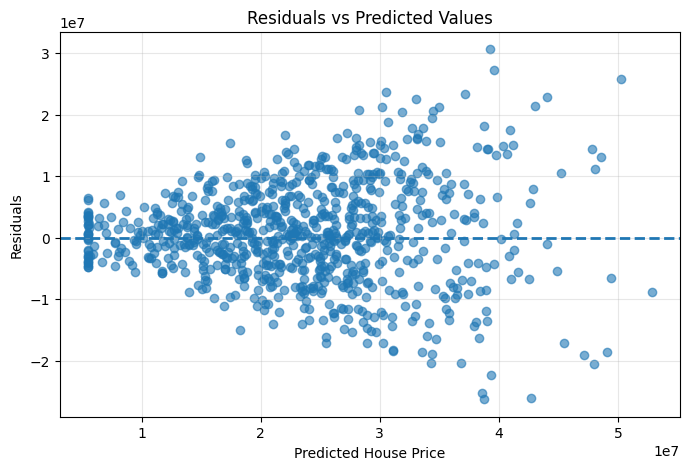

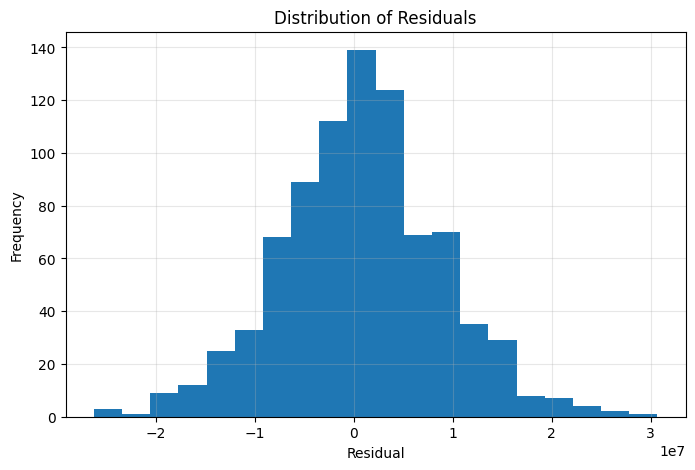

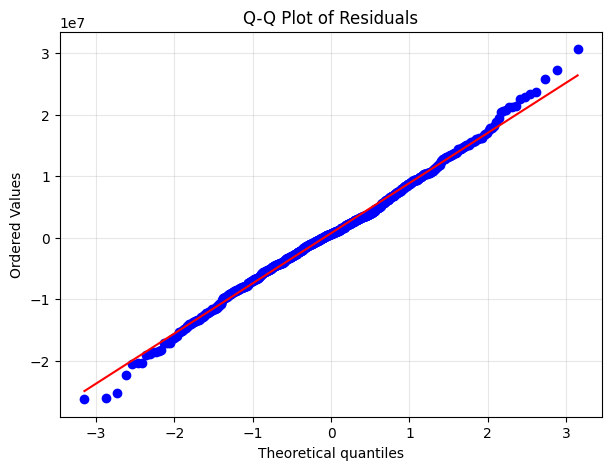

In [14]:
# 1. Calculate Residuals
residuals = Y_test_simple - Y_pred_simple
print("Mean Residual:", residuals.mean())

# 2. Plot Residuals vs Predicted Values
plt.figure(figsize=(8, 5))
plt.scatter(Y_pred_simple, residuals, alpha=0.6)
plt.axhline(y=0,linestyle="--",linewidth=2)
plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.grid(alpha=0.3)
plt.show() 

# 3. Plot Distribution of Residuals
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=20)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.grid(alpha=0.3)
plt.show()

# 4. Q-Q Plot
import scipy.stats as stats
plt.figure(figsize=(7, 5))
stats.probplot(residuals,dist="norm",plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.grid(alpha=0.3)
plt.show()

## Interpretation

The Linear Regression assumptions were evaluated using residual plots, a histogram, and a Q-Q plot.

- **Linearity:** Residuals are reasonably scattered around zero without a strong curved pattern, so linearity is reasonably satisfied.
- **Homoscedasticity:** The residual spread increases as predicted price increases, indicating some heteroscedasticity.
- **Normality:** The histogram is approximately bell-shaped and the Q-Q plot is mostly close to the diagonal line, so residuals are approximately normal.
- **Outliers:** Some extreme residuals are visible, indicating potential outliers.

### Conclusion

The Linear Regression model reasonably satisfies linearity and normality assumptions, but shows some heteroscedasticity and potential outliers.

---
---

# 📊 Part D: Model Evaluation Metrics


### 13. Evaluate the Simple Linear Regression model 

In [15]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

# MSE 
mse = mean_squared_error(Y_test_simple , Y_pred_simple)

# MAE
mae = mean_absolute_error(Y_test_simple , Y_pred_simple)

# RMSE
rmse = np.sqrt(mse)

# R² Score
r2 = r2_score(Y_test_simple , Y_pred_simple)

# Adjusted R² Score
n = len(Y_test_simple) # Number of test observations
p = X_test_simple.shape[1]  # Number of predictors
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)
print("Adjusted R² Score:", adjusted_r2)


MSE: 66989260021849.47
MAE: 6294593.696131912
RMSE: 8184696.696997969
R² Score: 0.5625199587991578
Adjusted R² Score: 0.5619979062440257


### 14. Interpretation of Evaluation Metrics

The Simple Linear Regression model was evaluated using MSE, MAE, RMSE, R², and Adjusted R².

- **MSE = 66,989,260,021,849.47:** Indicates the average squared prediction error. Lower values indicate better performance.
- **MAE = ₹6,294,593.70:** The model's predictions differ from actual house prices by approximately ₹62.95 lakh on average.
- **RMSE = ₹8,184,696.70:** The typical prediction error is approximately ₹81.85 lakh. Since RMSE is higher than MAE, some larger errors are present.
- **R² = 0.5625:** The model explains approximately 56.25% of the variation in house prices using `area_sqft`.
- **Adjusted R² = 0.5620:** The adjusted score is slightly lower than R² because it accounts for the number of predictors.

### Conclusion

The Simple Linear Regression model provides a moderate level of predictive performance. `area_sqft` explains a significant portion of house-price variation, but the relatively high MAE and RMSE indicate that prediction errors are still substantial.

----
----

# 📉 Part E: Multiple Linear Regression


### 15. Multiple Linear Regression

In [16]:
x_multiple = df[
    [
        "area_sqft",
        "bedrooms",
        "bathrooms",
        "location_score",
        "age_years",
        "distance_city_km",
        "lot_size_sqft",
        "has_garage",
        "has_pool",
        "renovation_years_ago"
    ]
]

y_multiple = df["house_price_inr"]

x_train_multiple, x_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    x_multiple , y_multiple , test_size = 0.2 , random_state = 42)

multiple_lr = LinearRegression()
multiple_lr.fit(x_train_multiple , y_train_multiple)

y_pred_multiple = multiple_lr.predict(x_test_multiple)

# Evaluate the model
# MSE 
mse_multiple = mean_squared_error(y_test_multiple , y_pred_multiple)

# MAE
mae_multiple = mean_absolute_error(y_test_multiple , y_pred_multiple)

# RMSE
rmse_multiple = np.sqrt(mse_multiple)

# R² Score
r2_multiple = r2_score(y_test_multiple , y_pred_multiple)

# Adjusted R² Score
n = len(y_test_multiple)
p = x_test_multiple.shape[1]
adjusted_r2_multiple = 1 - ((1 - r2_multiple) * (n - 1) / (n - p - 1))

print("MSE:", mse_multiple)
print("MAE:", mae_multiple)
print("RMSE:", rmse_multiple)
print("R² Score:", r2_multiple)
print("Adjusted R² Score:", adjusted_r2_multiple)

MSE: 12592918884127.742
MAE: 2604991.406155695
RMSE: 3548650.290480557
R² Score: 0.917760687750989
Adjusted R² Score: 0.916768657446417


### 16. Compare Simple vs Multiple Linear Regression

In [17]:
comparison = {
    "Metric": ["MSE", "MAE", "RMSE", "R²", "Adjusted R²" ] ,
    
    "Simple Linear Regression": [mse , mae , rmse , r2 , adjusted_r2 ] ,
    
    "Multiple Linear Regression": [mse_multiple , mae_multiple , rmse_multiple , r2_multiple , adjusted_r2_multiple ]
}

comparison_df = pd.DataFrame(comparison)

comparison_df

,Metric,Simple Linear Regression,Multiple Linear Regression
0,MSE,6.698926e+13,1.259292e+13
1,MAE,6.294594e+06,2.604991e+06
2,RMSE,8.184697e+06,3.548650e+06
3,R²,5.625200e-01,9.177607e-01
4,Adjusted R²,5.619979e-01,9.167687e-01



### Q17. Why Performance Improves or Degrades?

Simple Linear Regression uses only `area_sqft`, while Multiple Linear Regression uses several relevant features such as `bedrooms`, `bathrooms`, `location_score`, `distance_city_km`, and `lot_size_sqft`.

The Multiple Linear Regression model performed better because these additional features provide useful information for predicting house prices.

In our results, MAE decreased from approximately ₹62.95 lakh to ₹26.05 lakh, while RMSE decreased from ₹81.85 lakh to ₹35.49 lakh. R² also increased from 56.25% to 91.78%, showing that the model explains much more variation in house prices.

However, adding irrelevant or noisy features, multicollinearity, or overfitting can cause performance to degrade.

### Conclusion

Multiple Linear Regression provides significantly better performance because the additional relevant features improve the model's ability to explain and predict house prices.

---
---

# 🔁 Part F: Polynomial Regression


In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Polynomial degree
degree = 2

# Create polynomial model
poly_model = make_pipeline(PolynomialFeatures(degree=degree) , LinearRegression())

# Train model
poly_model.fit(X_train_simple , Y_train_simple)

# Predictions
y_pred_poly = poly_model.predict(X_test_simple)

# Evaluate Polynomial Regression
mse_poly = mean_squared_error(Y_test_simple , y_pred_poly)
mae_poly = mean_absolute_error(Y_test_simple , y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(Y_test_simple , y_pred_poly)
adjusted_r2_poly = 1 - ((1 - r2_poly) * (n - 1) / (n - p - 1))

print("Polynomial Regression Metrics")
print("MSE:", mse_poly)
print("MAE:", mae_poly)
print("RMSE:", rmse_poly)
print("R² Score:", r2_poly)
print("Adjusted R² Score:", adjusted_r2_poly)

Polynomial Regression Metrics
MSE: 66962947122198.21
MAE: 6292394.5612817025
RMSE: 8183089.094113434
R² Score: 0.5626917978136475
Adjusted R² Score: 0.5574166687161041


### 19. Linear vs Polynomial Regression

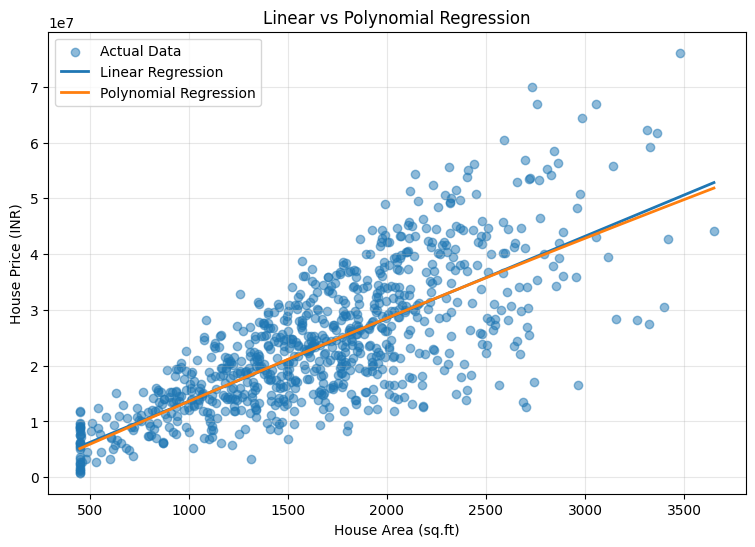

In [19]:
# Sort values for smooth curves
sorted_indices = X_test_simple["area_sqft"].argsort()

X_sorted = X_test_simple.iloc[sorted_indices]

y_linear_sorted = simple_lr.predict(X_sorted)
y_poly_sorted = poly_model.predict(X_sorted)

plt.figure(figsize=(9, 6))
plt.scatter(X_test_simple ["area_sqft"] , Y_test_simple , alpha=0.5 , label="Actual Data")
plt.plot(X_sorted ["area_sqft"] , y_linear_sorted , linewidth=2 , label="Linear Regression")
plt.plot(X_sorted ["area_sqft"] , y_poly_sorted , linewidth=2 , label="Polynomial Regression")
plt.xlabel("House Area (sq.ft)") 
plt.ylabel("House Price (INR)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [20]:
comparison_poly = {
    "Metric": ["MSE", "MAE", "RMSE", "R²", "Adjusted R²"],
    "Linear Regression": [mse, mae, rmse, r2, adjusted_r2],
    "Polynomial Regression": [mse_poly , mae_poly , rmse_poly , r2_poly , adjusted_r2_poly]
    }

comparison_poly_df = pd.DataFrame(comparison_poly)

comparison_poly_df.style.format({
    "Linear Regression": "{:,.2f}",
    "Polynomial Regression": "{:,.2f}"
})

,Metric,Linear Regression,Polynomial Regression
0,MSE,"66,989,260,021,849.47","66,962,947,122,198.21"
1,MAE,"6,294,593.70","6,292,394.56"
2,RMSE,"8,184,696.70","8,183,089.09"
3,R²,0.56,0.56
4,Adjusted R²,0.56,0.56


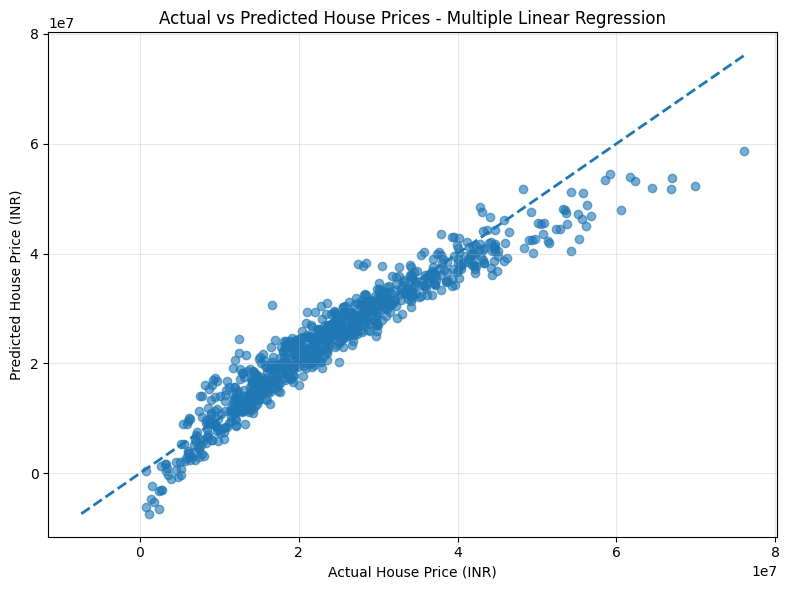

In [21]:
# Beat Linear Regression - Multiple Linear Regression
plt.figure(figsize=(8, 6))
plt.scatter(y_test_multiple, y_pred_multiple, alpha=0.6)

# Perfect prediction reference line
min_value = min(y_test_multiple.min(), y_pred_multiple.min())
max_value = max(y_test_multiple.max(), y_pred_multiple.max())

plt.plot([min_value, max_value],[min_value, max_value],linestyle="--",linewidth=2)
plt.xlabel("Actual House Price (INR)")
plt.ylabel("Predicted House Price (INR)")
plt.title("Actual vs Predicted House Prices - Multiple Linear Regression")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../Outputs/regression_plot.png", dpi=300)
plt.show()

### 20. Overfitting and Underfitting

Polynomial Regression can capture non-linear relationships by adding polynomial terms such as `area_sqft²`.

In this project, a degree-2 polynomial model was used. The Polynomial Regression results are very similar to the Simple Linear Regression results.

The R² score increased only slightly from 0.5625 to 0.5627, while Adjusted R² decreased from 0.5620 to 0.5574.

This indicates that adding the quadratic term did not provide significant additional predictive power.

There is no strong evidence of overfitting from these results. Instead, both models are limited because they use only `area_sqft` to predict house price.

### Conclusion

Degree-2 Polynomial Regression does not significantly improve the model. Using multiple relevant features is more effective for this house-price prediction problem.

----
-----

# ⚙️ Part G: Gradient Descent Optimization

### Q21. Gradient Descent – Conceptual Explanation

Gradient Descent is an optimization algorithm used to find the model parameters that minimize the prediction error.

For a Linear Regression model:

$$
\hat{y} = b_0 + b_1x
$$

Gradient Descent repeatedly updates the model parameters in the direction that reduces the loss function.

The general parameter update rule is:

$$
\theta_{new} = \theta_{old} - \alpha \frac{\partial J}{\partial \theta}
$$

Where:

- $\theta$ = Model parameter
- $\alpha$ = Learning rate
- $J$ = Loss/Cost function
- $\frac{\partial J}{\partial \theta}$ = Gradient

### Learning Rate

The learning rate controls the size of each parameter update.

- Very small learning rate → Slow convergence
- Very large learning rate → Unstable updates
- Appropriate learning rate → Faster and smoother convergence

### Intuition

Gradient Descent can be imagined as walking downhill on a mountain. The algorithm repeatedly moves in the direction that decreases the loss until it reaches a minimum.

### In This Project

Gradient Descent will be used to minimize the prediction error of the house-price regression model.

### Conclusion

Gradient Descent is an optimization technique that helps regression models find suitable parameters by repeatedly reducing the loss function.


### 22. Batch Gradient Descent from Scratch

Batch Gradient Descent is an optimization algorithm in which the gradient is calculated using the entire training dataset in every iteration.

The parameter update rule is:

$$
\theta_{new} = \theta_{old} - \alpha \nabla J(\theta)
$$

Where:

- $\theta$ = Model parameters
- $\alpha$ = Learning rate
- $\nabla J(\theta)$ = Gradient of the loss function

### Implementation Steps

1. Standardize the input features and target.
2. Add an intercept column to the feature matrix.
3. Initialize model parameters with zeros.
4. Calculate predictions.
5. Calculate prediction errors.
6. Calculate the Mean Squared Error loss.
7. Calculate the gradient using the complete training dataset.
8. Update the parameters.
9. Repeat for the specified number of epochs.
10. Store the loss values to analyze convergence.


Training Shape: (3360, 11)
Testing Shape: (840, 11) 

Learned Parameters:
[ 9.21590846e-17  6.76901802e-01  5.30086230e-02  9.82900427e-03
  5.32060848e-01 -7.38016195e-02 -7.11558190e-02  2.31140682e-02
  2.58817465e-03  1.07043753e-02 -1.25432611e-02] 

Batch Gradient Descent Metrics :
MSE: 12666180815040.064
MAE: 2611766.638894971
RMSE: 3558957.827094902
R² Score: 0.9172822434071715
Adjusted R² Score: 0.9162844417594895 



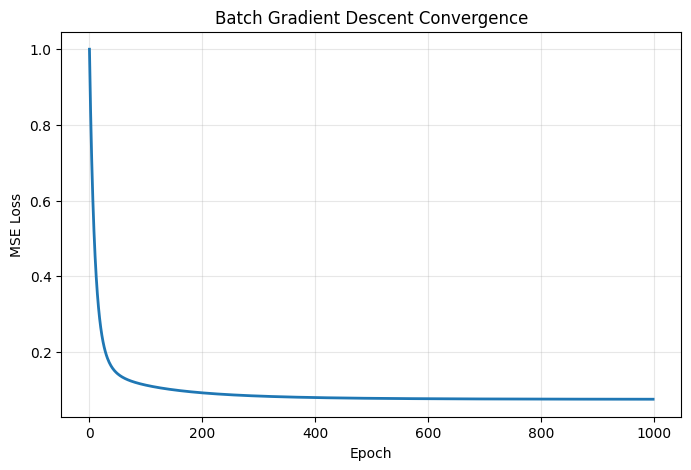

In [22]:
from sklearn.preprocessing import StandardScaler

# Standardize features
scaler_X = StandardScaler()

x_train_scaled = scaler_X.fit_transform(x_train_multiple)
x_test_scaled = scaler_X.transform(x_test_multiple)

# Target scaling
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_multiple.to_numpy().reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test_multiple.to_numpy().reshape(-1, 1)).ravel()

# Add a column of 1s for the intercept
x_train_gd = np.c_[np.ones(x_train_scaled.shape[0]),x_train_scaled]
x_test_gd = np.c_[np.ones(x_test_scaled.shape[0]),x_test_scaled]

print("Training Shape:", x_train_gd.shape)
print("Testing Shape:", x_test_gd.shape ,"\n")

# Batch Gradient Descent Function

def batch_gradient_descent(X, y, learning_rate=0.01, epochs=1000):
    
    n_samples, n_features = X.shape
    
    # Initialize parameters
    theta = np.zeros(n_features)
    
    # Store loss at every epoch
    loss_history = []
    
    for epoch in range(epochs):
        
        # Prediction
        y_pred = X @ theta
        
        # Error
        error = y_pred - y
        
        # Mean Squared Error
        loss = np.mean(error ** 2)
        loss_history.append(loss)
        
        # Gradient
        gradient = (2 / n_samples) * (X.T @ error)
        
        # Update parameters
        theta = theta - learning_rate * gradient
    
    return theta, loss_history

# Train the Model
theta_batch, batch_loss_history = batch_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=1000)
print("Learned Parameters:")
print(theta_batch , "\n")

# Make Predictions
y_pred_batch_scaled = x_test_gd @ theta_batch

# Convert predictions back to original INR scale
y_pred_batch = scaler_y.inverse_transform(y_pred_batch_scaled.reshape(-1, 1)).ravel()

# Evaluate Batch Gradient Descent
mse_batch = mean_squared_error(y_test_multiple, y_pred_batch)
mae_batch = mean_absolute_error(y_test_multiple, y_pred_batch)
rmse_batch = np.sqrt(mse_batch)
r2_batch = r2_score(y_test_multiple, y_pred_batch)
n = len(y_test_multiple)
p = x_train_multiple.shape[1]
adjusted_r2_batch = 1 - ((1 - r2_batch) * (n - 1) / (n - p - 1))

print("Batch Gradient Descent Metrics :")
print("MSE:", mse_batch)
print("MAE:", mae_batch)
print("RMSE:", rmse_batch)
print("R² Score:", r2_batch)
print("Adjusted R² Score:", adjusted_r2_batch , "\n")

# Plot Convergence

plt.figure(figsize=(8, 5))
plt.plot(batch_loss_history, linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Batch Gradient Descent Convergence")
plt.grid(alpha=0.3)
plt.show()





### Why Scaling is Used

Gradient Descent is sensitive to feature scale. Since the dataset contains features with very different numerical ranges, standardization helps the optimization process converge more smoothly.

### Conclusion

Batch Gradient Descent successfully learns the regression parameters by using the complete training dataset at every iteration. The decreasing loss curve shows the convergence behavior of the optimization process.

## Q23. Stochastic Gradient Descent (SGD)

Stochastic Gradient Descent is an optimization method that updates model parameters using one training sample at a time.

Unlike Batch Gradient Descent, which uses the complete training dataset for each update, SGD performs a parameter update after every individual sample.

### Working Steps

1. Shuffle the training data.
2. Select one training sample.
3. Calculate the prediction.
4. Calculate the error.
5. Calculate the gradient for that sample.
6. Update the model parameters.
7. Repeat for all training samples.
8. Repeat the process for multiple epochs.


Learned Parameters:
[-3.39597331e-02  7.09657568e-01  1.46630861e-02  1.74400787e-02
  5.19891555e-01 -5.72513953e-02 -7.01479614e-02 -1.15843513e-02
  2.61623462e-04 -3.05981870e-02 -8.97576164e-03] 

Stochastic Gradient Descent Metrics:
MSE: 13434971666428.46
MAE: 2661795.338014417
RMSE: 3665374.6965935775
R² Score: 0.9122615781060393
Adjusted R² Score: 0.9112032135476079


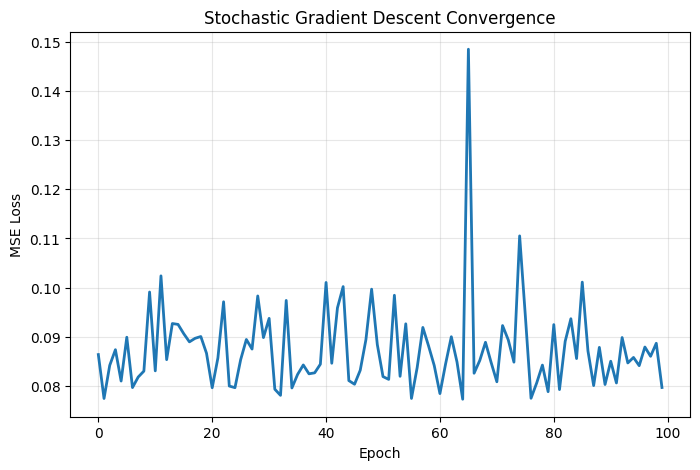

In [23]:
# 1 — SGD Function
def stochastic_gradient_descent(X,y,learning_rate=0.01,epochs=100):
    
    n_samples, n_features = X.shape
    
    # Initialize parameters
    theta = np.zeros(n_features)
    
    # Store average loss after every epoch
    loss_history = []
    
    for epoch in range(epochs):
        
        # Shuffle training data
        indices = np.random.permutation(n_samples)
        
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        # Update parameters using one sample at a time
        for i in range(n_samples):
            
            # Select one sample
            x_i = X_shuffled[i]
            y_i = y_shuffled[i]
            
            # Prediction
            y_pred = x_i @ theta
            
            # Error
            error = y_pred - y_i
            
            # Gradient for one sample
            gradient = 2 * x_i * error
            
            # Update parameters
            theta = theta - learning_rate * gradient
        
        # Calculate loss for the complete training set
        y_pred_all = X @ theta
        loss = np.mean((y_pred_all - y) ** 2)
        loss_history.append(loss)
    
    return theta, loss_history

# 2 — Train SGD Model
theta_sgd, sgd_loss_history = stochastic_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=100)

print("Learned Parameters:")
print(theta_sgd , "\n")

# 3 — Make Predictions
y_pred_sgd_scaled = x_test_gd @ theta_sgd

# Convert predictions back to original INR scale
y_pred_sgd = scaler_y.inverse_transform(y_pred_sgd_scaled.reshape(-1, 1)).ravel()

# 4 — Evaluate SGD
mse_sgd = mean_squared_error(y_test_multiple, y_pred_sgd)
mae_sgd = mean_absolute_error(y_test_multiple, y_pred_sgd)
rmse_sgd = np.sqrt(mse_sgd)
r2_sgd = r2_score(y_test_multiple, y_pred_sgd)

n = len(y_test_multiple)
p = x_train_multiple.shape[1]

adjusted_r2_sgd = 1 - ((1 - r2_sgd) * (n - 1) / (n - p - 1))

print("Stochastic Gradient Descent Metrics:")
print("MSE:", mse_sgd)
print("MAE:", mae_sgd)
print("RMSE:", rmse_sgd)
print("R² Score:", r2_sgd)
print("Adjusted R² Score:", adjusted_r2_sgd)

# 5 — SGD Convergence Plot
plt.figure(figsize=(8, 5))
plt.plot(sgd_loss_history,linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Stochastic Gradient Descent Convergence")
plt.grid(alpha=0.3)
plt.show()

### Key Difference from Batch Gradient Descent and Stochastic Gradient Descent

- **Batch GD:** Uses the complete dataset for each parameter update.
- **SGD:** Uses one sample for each parameter update.

### Advantages

- Faster individual updates.
- Suitable for large datasets.
- Can start improving the model quickly.

### Disadvantage

Because each update is based on only one sample, the optimization path can be noisy and the loss curve may fluctuate.

### Conclusion

SGD updates model parameters much more frequently than Batch Gradient Descent. It can converge quickly, but its convergence path is generally noisier than Batch Gradient Descent.

### 24. Implement Mini-Batch Gradient Descent

Mini-Batch Gradient Descent is an optimization technique that updates model parameters using a small batch of training samples at a time.

It combines the advantages of Batch Gradient Descent and Stochastic Gradient Descent.

### Working Steps

1. Shuffle the training data.
2. Divide the training data into small batches.
3. Calculate predictions for one mini-batch.
4. Calculate the error.
5. Calculate the gradient using the mini-batch.
6. Update the model parameters.
7. Repeat for all mini-batches.
8. Repeat the process for multiple epochs.

In this implementation, a batch size of **32** is used.


Learned Parameters:
[ 7.06406523e-04  7.07803280e-01  2.61421031e-02  1.55495816e-02
  5.33883266e-01 -8.00646752e-02 -6.90402365e-02  1.56092268e-02
  7.19623395e-04  1.08026693e-02 -1.48457106e-02] 

Mini-Batch Gradient Descent Metrics:
MSE: 12598921562532.229
MAE: 2604452.556615249
RMSE: 3549495.958940118
R² Score: 0.9177214866612194
Adjusted R² Score: 0.9167289834846358


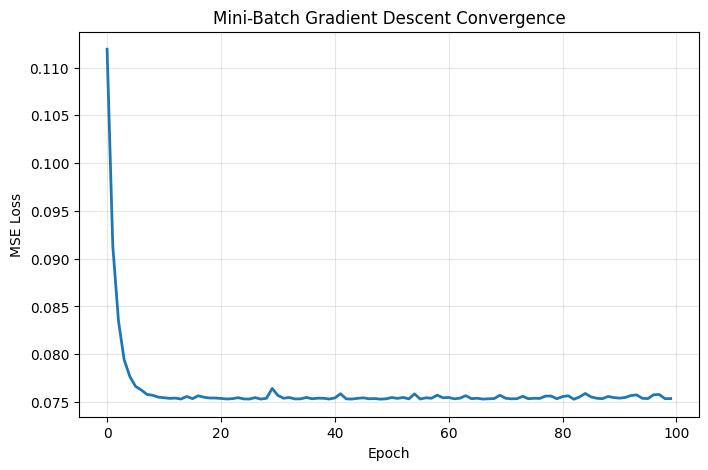

In [24]:
# Mini-Batch Gradient Descent Function
def mini_batch_gradient_descent(X,y,learning_rate=0.01,epochs=100,batch_size=32):
    
    n_samples, n_features = X.shape
    
    # Initialize parameters
    theta = np.zeros(n_features)
    
    # Store loss after every epoch
    loss_history = []
    
    for epoch in range(epochs):
        
        # Shuffle training data
        indices = np.random.permutation(n_samples)
        
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        # Process data in mini-batches
        for start in range(0, n_samples, batch_size):
            
            end = start + batch_size
            
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
            
            # Prediction
            y_pred = X_batch @ theta
            
            # Error
            error = y_pred - y_batch
            
            # Gradient using mini-batch
            gradient = (2 / len(X_batch)) * (X_batch.T @ error)
            
            # Update parameters
            theta = theta - learning_rate * gradient
        
        # Calculate loss on complete training data
        y_pred_all = X @ theta
        loss = np.mean((y_pred_all - y) ** 2)
        loss_history.append(loss)
    
    return theta, loss_history

# Train Mini-Batch Model
theta_mini_batch, mini_batch_loss_history = mini_batch_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=100,batch_size=32)

print("Learned Parameters:")
print(theta_mini_batch , "\n")

# Predictions
y_pred_mini_batch_scaled = x_test_gd @ theta_mini_batch

# Convert predictions back to original INR scale
y_pred_mini_batch = scaler_y.inverse_transform(y_pred_mini_batch_scaled.reshape(-1, 1)).ravel()

# Evaluation
mse_mini_batch = mean_squared_error(y_test_multiple, y_pred_mini_batch)
mae_mini_batch = mean_absolute_error(y_test_multiple,y_pred_mini_batch)
rmse_mini_batch = np.sqrt(mse_mini_batch)
r2_mini_batch = r2_score(y_test_multiple,y_pred_mini_batch)
n = len(y_test_multiple)
p = x_train_multiple.shape[1]
adjusted_r2_mini_batch = 1 - ((1 - r2_mini_batch) * (n - 1) / (n - p - 1))

print("Mini-Batch Gradient Descent Metrics:")
print("MSE:", mse_mini_batch)
print("MAE:", mae_mini_batch)
print("RMSE:", rmse_mini_batch)
print("R² Score:", r2_mini_batch)
print("Adjusted R² Score:", adjusted_r2_mini_batch)

# Convergence Plot
plt.figure(figsize=(8, 5))
plt.plot(mini_batch_loss_history,linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Mini-Batch Gradient Descent Convergence")
plt.grid(alpha=0.3)
plt.show()

### Comparison

- **Batch GD:** Uses the complete dataset for each update.
- **SGD:** Uses one sample for each update.
- **Mini-Batch GD:** Uses a small group of samples for each update.

### Advantages

- Faster updates than Batch Gradient Descent.
- More stable than SGD.
- Efficient for larger datasets.
- Provides a good balance between computational efficiency and convergence stability.

### Conclusion

Mini-Batch Gradient Descent provides a practical compromise between Batch Gradient Descent and SGD by using a small number of samples for each parameter update.

## Q25. Comparison of Batch GD, SGD and Mini-Batch GD

The three Gradient Descent optimization methods were compared based on their convergence behavior and training time.

### Convergence Behavior

- **Batch Gradient Descent:** Uses the complete training dataset for each update, resulting in a relatively smooth convergence curve.
- **Stochastic Gradient Descent:** Uses one sample at a time, resulting in more frequent but noisier parameter updates. Therefore, its loss curve may fluctuate.
- **Mini-Batch Gradient Descent:** Uses a small group of samples for each update. It generally provides a balance between the smoothness of Batch GD and the frequent updates of SGD.

### Training Time

Training time was measured using Python's `time.perf_counter()`.

The actual training time can vary depending on the system and the number of epochs used.

### Overall Comparison

| Method | Data per Update | Convergence | Training Behavior |
|---|---|---|---|
| Batch GD | Entire dataset | Smooth | Stable but computationally heavier per update |
| SGD | 1 sample | Noisy | Frequent updates |
| Mini-Batch GD | Small batch | Moderately smooth | Good balance |


Batch GD Training Time: 0.016585700010182336 seconds
SGD Training Time: 1.0693300999992061 seconds
Mini-Batch GD Training Time: 0.05261029998655431 seconds


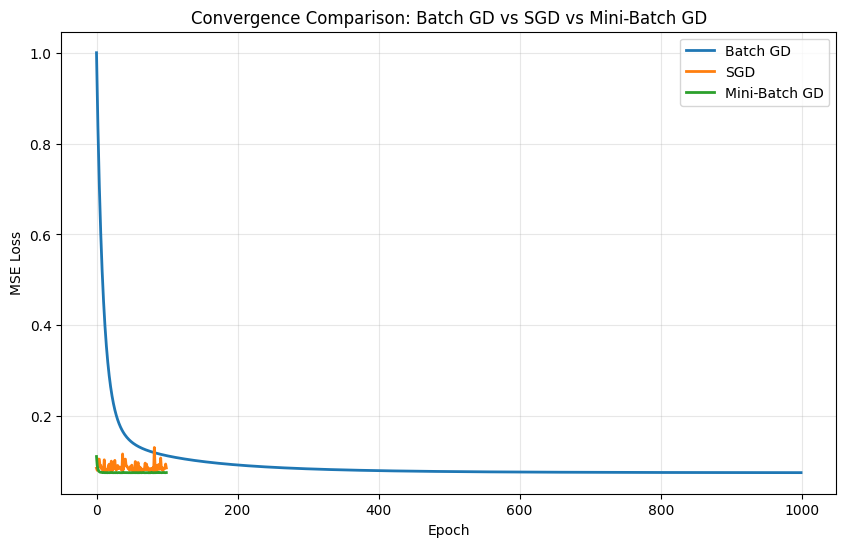

,Method,Training Time (seconds),Final Loss
0,Batch GD,0.016586,0.075487
1,SGD,1.069330,0.085841
2,Mini-Batch GD,0.052610,0.075609


In [25]:
import time

#Batch Gradient Descent
start_time = time.perf_counter()
theta_batch, batch_loss_history = batch_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=1000)
batch_time = time.perf_counter() - start_time
print("Batch GD Training Time:", batch_time, "seconds")

# SGD
start_time = time.perf_counter()
theta_sgd, sgd_loss_history = stochastic_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=100)
sgd_time = time.perf_counter() - start_time
print("SGD Training Time:", sgd_time, "seconds")

# Mini-Batch GD
start_time = time.perf_counter()
theta_mini_batch, mini_batch_loss_history = mini_batch_gradient_descent(x_train_gd,y_train_scaled,learning_rate=0.01,epochs=100,batch_size=32)
mini_batch_time = time.perf_counter() - start_time
print("Mini-Batch GD Training Time:", mini_batch_time, "seconds")

# Convergence Graph
plt.figure(figsize=(10, 6))
plt.plot(batch_loss_history,linewidth=2,label="Batch GD")
plt.plot(sgd_loss_history,linewidth=2,label="SGD")
plt.plot(mini_batch_loss_history,linewidth=2,label="Mini-Batch GD")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Convergence Comparison: Batch GD vs SGD vs Mini-Batch GD")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../Outputs/gradient_descent_comparison.png", dpi=300)
plt.show()

# Training Time Comparison
training_time_df = pd.DataFrame({
    
    "Method": ["Batch GD","SGD","Mini-Batch GD"],

    "Training Time (seconds)": [batch_time,sgd_time,mini_batch_time] ,

    "Final Loss": [batch_loss_history[-1],sgd_loss_history[-1],mini_batch_loss_history[-1]]
})

training_time_df.style.format({
    "Training Time (sec)": "{:.6f}",
    "Final Loss": "{:.6f}"
})

## Q27. Effect of Model Complexity on Prediction Error

Model complexity determines how flexibly a model can learn relationships from the training data.

- **Low complexity:** A model may underfit the data because it cannot capture important patterns. Both training and testing errors may be high.
- **Appropriate complexity:** The model captures meaningful patterns and generalizes well to unseen data.
- **High complexity:** A model may overfit by learning noise and specific details of the training data. Training error may be low while testing error increases.

As model complexity increases, bias generally decreases, while variance and overfitting risk may increase.

### Conclusion
The goal is not to select the most complex model, but to select a model that achieves low prediction error and generalizes well to unseen data.

## Q28. Model with the Best Bias–Variance Balance

Among the three evaluated models, Multiple Linear Regression currently provides the best observed predictive performance.

It achieved a test R² score of approximately 0.9178 and an RMSE of approximately ₹35.49 lakh. In comparison, Simple Linear Regression and Degree-2 Polynomial Regression achieved R² scores of approximately 0.5625 and 0.5627, respectively.

Multiple Linear Regression benefits from using several relevant house features rather than relying only on `area_sqft`. Polynomial Regression adds a quadratic term, but its improvement over Simple Linear Regression is negligible.

### Conclusion
Multiple Linear Regression is the preferred model based on the available test results. Training-versus-test comparisons and cross-validation should be used to confirm whether it generalizes consistently and maintains a good bias–variance balance.

----
----

# 🧾 Part I: Final Analysis & Reporting




### 1. Project Overview

The objective of this project was to predict house prices using machine learning regression techniques. The dataset contains house-related features such as area, bedrooms, bathrooms, location score, distance from the city, and other property characteristics.

Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, and three Gradient Descent optimization approaches were evaluated.

### 2. Best-Performing Model

Multiple Linear Regression was the best-performing model among the three regression models evaluated.

- **Test R² Score:** Approximately 0.9178
- **Test RMSE:** Approximately ₹35.49 lakh
- **Test MAE:** Approximately ₹26.05 lakh

The model performed better than Simple Linear Regression and Degree-2 Polynomial Regression because it used multiple relevant property features instead of relying only on `area_sqft`.

### 3. Impact of Gradient Descent Optimization

Batch Gradient Descent, Stochastic Gradient Descent (SGD), and Mini-Batch Gradient Descent were implemented from scratch to optimize regression parameters.

Feature and target standardization helped improve numerical stability during optimization. The loss curves were used to study convergence behavior.

- **Batch GD:** Updates parameters using the entire training dataset in each iteration.
- **SGD:** Updates parameters using one training sample at a time.
- **Mini-Batch GD:** Updates parameters using a small group of samples.

Their relative convergence speed, loss reduction, and training time depend on the learning rate, number of epochs, batch size, and dataset. The measured results should be used to identify which approach worked best in this experiment.

### 4. Evidence of Overfitting and Underfitting

Simple Linear Regression and Polynomial Regression achieved test R² scores of approximately 0.5625 and 0.5627, respectively. This suggests that using only `area_sqft` did not capture all the information needed to predict house prices accurately.

Multiple Linear Regression achieved a substantially higher test R² score of approximately 0.9178, indicating a much better fit on the test dataset.

The available test results do not, by themselves, prove overfitting. Comparing training and test performance, preferably with cross-validation, would provide stronger evidence of overfitting or underfitting.

### 5. Practical Business Interpretation

The results suggest that house prices are influenced by multiple property characteristics, not just the total area. Features such as the number of bedrooms, location score, lot size, and distance from the city can contribute useful predictive information.

A model with an R² score of approximately 0.9178 explains about 91.78% of the variation in house prices on the evaluated test dataset. The RMSE of approximately ₹35.49 lakh indicates the scale of prediction error, with larger errors having a stronger effect on RMSE.

The model could support preliminary property valuation, pricing analysis, and real-estate decision-making. However, predictions should be validated on new properties before being used for actual financial or business decisions.

### 6. Final Conclusion

This project demonstrated the complete regression workflow, including exploratory data analysis, feature selection, model training, evaluation, and optimization using Gradient Descent.

Multiple Linear Regression was the strongest model among the evaluated regression models. Using multiple relevant features improved predictive performance considerably compared with using area alone.

Further improvements could include cross-validation, residual analysis, hyperparameter tuning, and testing on additional real-world property data.